# BrandPulse AI: Sentiment Analysis on Twitter Data using Deep Learning (Bi-LSTM)

## 1. Importing Libraries and Loading the Cleaned Data

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf

print("TensorFlow:", tf.__version__)

df = pd.read_csv("clean_tweets.csv")
print(df.shape)
df[["clean_text", "airline_sentiment"]].head()

TensorFlow: 2.22.0-rc0
(14396, 6)


,clean_text,airline_sentiment
0,say,neutral
1,plus add commercial experience tacky,positive
2,today must mean need take another trip,neutral
3,really aggressive blast obnoxious entertainmen...,negative
4,really big bad thing,negative


## 2. Train-Test Split, Tokenization and Padding

In [ ]:
from sklearn.model_selection import train_test_split
from collections import Counter

# 1. Same split as Day 2
X_tr, X_te, y_tr, y_te = train_test_split(
    df["clean_text"], df["airline_sentiment"],
    test_size=0.2, stratify=df["airline_sentiment"], random_state=42)

classes = ["negative", "neutral", "positive"]
label_to_id = {c: i for i, c in enumerate(classes)}
ytr = y_tr.map(label_to_id).values
yte = y_te.map(label_to_id).values


VOCAB_SIZE = 10000
counts = Counter(w for t in X_tr for w in t.split())
top_words = [w for w, _ in counts.most_common(VOCAB_SIZE - 2)]
word_index = {w: i + 2 for i, w in enumerate(top_words)}

def encode(text):
    return [word_index.get(w, 1) for w in text.split()]

# 2. Pad / cut to a fixed length
MAXLEN = 15
def pad(seqs):
    arr = np.zeros((len(seqs), MAXLEN), dtype="int32")
    for i, s in enumerate(seqs):
        s = s[:MAXLEN]
        if len(s):
            arr[i, MAXLEN - len(s):] = s   # zeros go at the front
    return arr

Ptr = pad([encode(t) for t in X_tr])
Pte = pad([encode(t) for t in X_te])

print("Train:", Ptr.shape, " Test:", Pte.shape)
print("Example text :", X_tr.iloc[0])
print("Example ids  :", Ptr[0])

Train: (11516, 15)  Test: (2880, 15)
Example text : loyal southwest begin unhappy devaluation
Example ids  : [   0    0    0    0    0    0    0    0    0    0  445  292  740  855
 3890]


## 3.Building the LSTM mode

In [3]:
from tensorflow.keras import layers, models
from sklearn.utils.class_weight import compute_class_weight

tf.keras.utils.set_random_seed(42)

model = models.Sequential([
    layers.Input(shape=(MAXLEN,)),
    layers.Embedding(VOCAB_SIZE, 64),
    layers.Bidirectional(layers.LSTM(64)),
    layers.Dropout(0.5),
    layers.Dense(32, activation="relu"),
    layers.Dense(3, activation="softmax"),
])

model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

weights = compute_class_weight("balanced", classes=np.array([0, 1, 2]), y=ytr)
class_weights = {i: w for i, w in enumerate(weights)}
print("Class weights:", {classes[i]: round(w, 2) for i, w in class_weights.items()})

model.summary()

Class weights: {'negative': np.float64(0.53), 'neutral': np.float64(1.58), 'positive': np.float64(2.1)}


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 15, 64)         │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        66,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 710,275 (2.71 MB)

 Trainable params: 710,275 (2.71 MB)

 Non-trainable params: 0 (0.00 B)

## 4. Training the Model with Early Stopping

In [4]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)

history = model.fit(
    Ptr, ytr,
    validation_split=0.1,
    epochs=15,
    batch_size=64,
    class_weight=class_weights,
    callbacks=[early_stop],
)

Epoch 1/15
162/162 ━━━━━━━━━━━━━━━━━━━━ 6s 24ms/step - accuracy: 0.6141 - loss: 0.8663 - val_accuracy: 0.7561 - val_loss: 0.5970
Epoch 2/15
162/162 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.7810 - loss: 0.5788 - val_accuracy: 0.7821 - val_loss: 0.5445
Epoch 3/15
162/162 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.8434 - loss: 0.4185 - val_accuracy: 0.7691 - val_loss: 0.6110
Epoch 4/15
162/162 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.8795 - loss: 0.3292 - val_accuracy: 0.7639 - val_loss: 0.6883


## 5. Training and Validation Curves

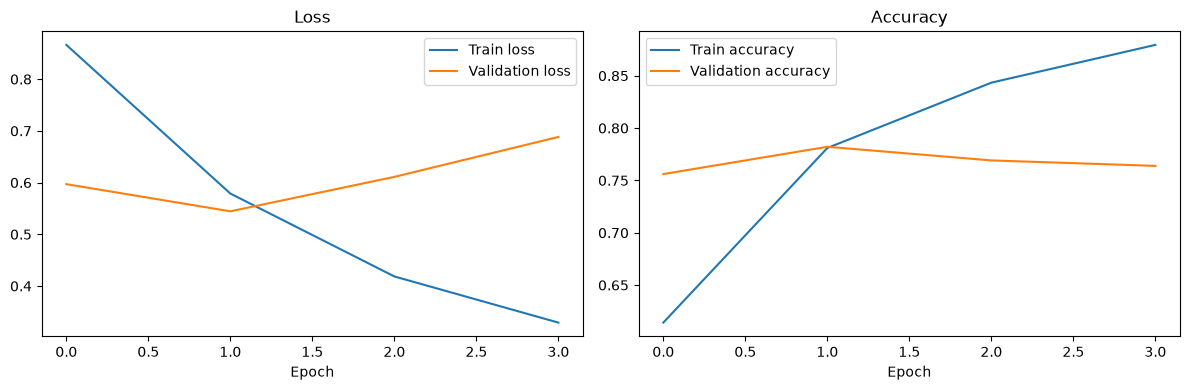

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["loss"], label="Train loss")
axes[0].plot(history.history["val_loss"], label="Validation loss")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history.history["accuracy"], label="Train accuracy")
axes[1].plot(history.history["val_accuracy"], label="Validation accuracy")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

 ## 6. Model Evaluation: Accuracy, Precision, Recall and F1-Score

In [6]:
from sklearn.metrics import classification_report, accuracy_score, precision_recall_fscore_support

probs = model.predict(Pte, verbose=0)
pred = probs.argmax(axis=1)

print("Accuracy:", round(accuracy_score(yte, pred), 4))
print(classification_report(yte, pred, target_names=classes))

p, r, f, _ = precision_recall_fscore_support(yte, pred, average="macro")
print("Macro  Precision:", round(p, 4), " Recall:", round(r, 4), " F1:", round(f, 4))

Accuracy: 0.7684
              precision    recall  f1-score   support

    negative       0.87      0.85      0.86      1815
     neutral       0.58      0.52      0.55       608
    positive       0.62      0.77      0.69       457

    accuracy                           0.77      2880
   macro avg       0.69      0.71      0.70      2880
weighted avg       0.77      0.77      0.77      2880

Macro  Precision: 0.6924  Recall: 0.7139  F1: 0.7


## 7.Confusion matrix

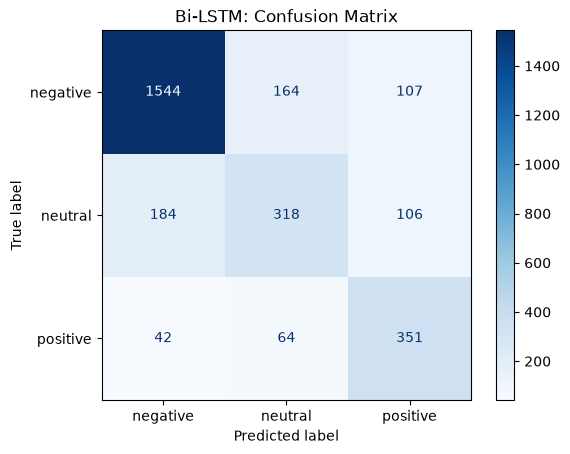

In [7]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    yte, pred, display_labels=classes, cmap="Blues")
plt.title("Bi-LSTM: Confusion Matrix")
plt.show()

## 8. Testing with Custom Inputs

In [8]:
from utils import clean

def predict_lstm(text):
    ids = pad([encode(clean(text))])
    p = model.predict(ids, verbose=0)[0]
    return classes[p.argmax()], round(float(p.max()), 2)

tests = [
    "The service was amazing!",
    "I waited 4 hours just to get a cold burger.",
    "The flight was okay, nothing special.",
    "Great, another delayed flight. Just what I needed.",
    "Thank you for the quick help with my baggage!",
]

for t in tests:
    label, conf = predict_lstm(t)
    print(f"{t}\n   LSTM: {label} (confidence {conf})\n")

The service was amazing!
   LSTM: positive (confidence 0.91)

I waited 4 hours just to get a cold burger.
   LSTM: negative (confidence 0.91)

The flight was okay, nothing special.
   LSTM: negative (confidence 0.86)

Great, another delayed flight. Just what I needed.
   LSTM: neutral (confidence 0.41)

Thank you for the quick help with my baggage!
   LSTM: positive (confidence 0.94)



## 9. Saving the Model and Comparison results

In [11]:
import json

model.save("lstm_model.keras")
with open("word_index.json", "w") as f:
    json.dump(word_index, f)

acc = accuracy_score(yte, pred)
p, r, f1, _ = precision_recall_fscore_support(yte, pred, average="macro")
lstm_row = pd.DataFrame([{"Model": "Bi-LSTM", "Accuracy": round(acc, 4),
                          "Precision": round(p, 4), "Recall": round(r, 4),
                          "F1 (macro)": round(f1, 4)}])

all_results = pd.concat([pd.read_csv("classical_results.csv"), lstm_row], ignore_index=True)
all_results.to_csv("all_results.csv", index=False)
all_results

,Model,Accuracy,Precision,Recall,F1 (macro)
0,TF-IDF + Logistic Regression,0.7705,0.7068,0.7356,0.7190
1,TF-IDF + Naive Bayes,0.7156,0.7804,0.5025,0.5352
2,Bi-LSTM,0.7684,0.6924,0.7139,0.7000


## Observations:

| Model | Accuracy | Precision | Recall | F1 (macro) |
|---|---|---|---|---|
| TF-IDF + Logistic Regression | 0.7705 | 0.7068 | 0.7356 | 0.7190 |
| TF-IDF + Naive Bayes | 0.7156 | 0.7804 | 0.5025 | 0.5352 |
| Bi-LSTM | 0.7684 | 0.6924 | 0.7139 | 0.7000 |

- The model has an Embedding layer, a Bidirectional LSTM, Dropout, and a Dense softmax layer. I used the same train/test split as Notebook 1 so the comparison is fair.
- Overfitting started quickly. Validation loss was lowest at epoch 2 and then went up while training loss kept going down. EarlyStopping stopped training at epoch 4 and went back to the epoch 2 weights.
- I expected the LSTM to win, but it did not. Its accuracy (0.7684) is almost the same as Logistic Regression (0.7705). I think the dataset is too small (about 11,500 training tweets) for the LSTM to learn much extra context.
- The LSTM is a bit better on negative tweets (F1 0.86) and misses fewer real complaints (164 negative tweets predicted as neutral, compared to 242 for Logistic Regression). But it is worse on neutral tweets (F1 0.55 against 0.60).
- Neutral tweets are the hardest class. The LSTM confuses them with negative (184) and positive (106).
- On my own sentences, it got both brief examples right. "The flight was okay, nothing special" was predicted negative with high confidence (0.86), which is wrong. The sarcastic tweet was predicted neutral with low confidence (0.41), because "great" and "delayed" pull in opposite directions.
- Overall, Logistic Regression is faster, easier to explain, and just as good on this data. The LSTM would probably do better with a much bigger dataset like Sentiment140 or with pre-trained embeddings.